# Datos Faltantes

In [18]:
 # Importar librerías necesarias
import pandas as pd  # Manejo de estructuras de datos bidimensionales (DataFrames y Series).
import numpy as np  # Operaciones numéricas avanzadas y soporte para el objeto nulo np.nan.
from sklearn.datasets import load_diabetes  # Carga el dataset de prueba de diabetes integrado en Scikit-Learn.
from sklearn.impute import (
    KNNImputer,
    SimpleImputer,
)  # Importa las clases para imputar nulos (Simple = media/mediana, KNN = vecinos).
import matplotlib.pyplot as plt  # Creación de gráficos sencillos y control de la figura.
import seaborn as sns  # Gráficos estadísticos avanzados (como histogramas y mapas de calor).

In [19]:
# Cargar el conjunto de datos
diabetes = load_diabetes(
    as_frame=True
)  # Carga el dataset en un objeto de Scikit-Learn estructurado como DataFrame.
data = (
    diabetes.data
)  # Extrae la tabla con las 10 características explicativas (edad, IMC, presión, etc.).
data["target"] = (
    diabetes.target
)  # Agrega la columna objetivo (nivel de progresión de la enfermedad) al DataFrame.

In [20]:
# Muestra una muestra aleatoria de 10 filas del DataFrame para inspeccionar sus datos.
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
385,0.023546,0.050680,-0.019140,0.049415,-0.063487,-0.061125,0.004460,-0.039493,-0.025953,-0.013504,219.0
300,0.016281,-0.044642,0.073552,-0.041235,-0.004321,-0.013527,-0.013948,-0.001116,0.042897,0.044485,275.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
42,-0.060003,0.050680,-0.010517,-0.014863,-0.049727,-0.023547,-0.058127,0.015858,-0.009919,-0.034215,61.0
311,0.096197,-0.044642,0.040140,-0.057313,0.045213,0.060690,-0.021311,0.036154,0.012551,0.023775,180.0
200,0.056239,-0.044642,-0.057941,-0.007977,0.052093,0.049103,0.056003,-0.021412,-0.028323,0.044485,158.0
271,0.038076,0.050680,0.008883,0.042529,-0.042848,-0.021042,-0.039719,-0.002592,-0.018114,0.007207,127.0
76,-0.030942,0.050680,0.028284,0.070072,-0.126781,-0.106845,-0.054446,-0.047981,-0.030748,0.015491,170.0


In [21]:
# Simular valores faltantes
# Establece la semilla aleatoria para garantizar la reproducibilidad de los resultados.
np.random.seed(42)
# Establece la semilla aleatoria para garantizar la reproducibilidad de los resultados.

# Selecciona aleatoriamente el 10% de los índices y asigna NaN a la columna 'bmi'.
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
# Selecciona aleatoriamente el 10% de los índices y asigna NaN a la columna 'bp'.
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [22]:
# Conteo de valores faltantes por columna
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [23]:
# Instanciamos la herramienta ajustando la estrategia a "mean" (media)
imputador_simple_bmi = SimpleImputer(strategy="mean")

# Creamos un NUEVO DataFrame 'df_clean_simple' copiando la tabla original 
# para no perder los datos nulos originales de 'data'
df_clean_simple = data.copy()

# Tomamos la columna 'bmi' (matriz 2D), le aplicamos el imputador y guardamos el resultado en la copia
df_clean_simple['bmi'] = imputador_simple_bmi.fit_transform(data[['bmi']])

# Verificamos si aún quedan datos faltantes en el nuevo DataFrame
df_clean_simple.isnull().sum()

age        0
sex        0
bmi        0
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [24]:
# PASO 1: Instanciamos la herramienta KNNImputer.
# n_neighbors=2 le indica que cuando encuentre un dato nulo en una fila, busque las 2 filas 
# con datos existentes que más se le parezcan para calcular el valor con el que llenará el hueco.
imputador_avanzado = KNNImputer(n_neighbors=2)

# PASO 2: Procesamos los datos y creamos un NUEVO DataFrame llamado df_clean_knn:
# A) data[['bmi', 'bp']] -> Extraemos únicamente las columnas 'bmi' y 'bp' en formato de tabla (matriz 2D).
# B) imputador_avanzado.fit_transform(...) -> Calcula los reemplazos basados en los vecinos más cercanos y llena los nulos. Retorna una matriz de números planos sin etiquetas.
# C) pd.DataFrame(..., columns=['bmi', 'bp']) -> Tomamos esa matriz de números planos y la empaquetamos dentro de una NUEVA variable (un nuevo DataFrame llamado 'df_clean_knn'), asignándole explícitamente sus nombres de columna.
df_clean_knn = pd.DataFrame(imputador_avanzado.fit_transform(data[['bmi', 'bp']]), columns=['bmi', 'bp'])

# PASO 1: Generamos el resumen estadístico de la columna 'bmi' imputada con la media simple (guardada en el DataFrame original 'data')
# Nos muestra el conteo, promedio, desviación estándar, mínimos, máximos y percentiles.
print("--- RESUMEN CON IMPUTACIÓN SIMPLE (MEDIA) ---")
print(data['bmi'].describe())

# PASO 2: Generamos el resumen estadístico de la columna 'bmi' imputada con KNN (guardada en el nuevo DataFrame 'df_clean_knn')
# Permite comparar cómo cambió la distribución al usar vecinos más cercanos en lugar de un valor fijo.
print("\n--- RESUMEN CON IMPUTACIÓN AVANZADA (KNN) ---")
print(df_clean_knn['bmi'].describe())

--- RESUMEN CON IMPUTACIÓN SIMPLE (MEDIA) ---
count    398.000000
mean      -0.000205
std        0.046989
min       -0.089197
25%       -0.035037
50%       -0.007284
75%        0.030440
max        0.160855
Name: bmi, dtype: float64

--- RESUMEN CON IMPUTACIÓN AVANZADA (KNN) ---
count    442.000000
mean       0.000567
std        0.045569
min       -0.089197
25%       -0.032073
50%       -0.006206
75%        0.029092
max        0.160855
Name: bmi, dtype: float64


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

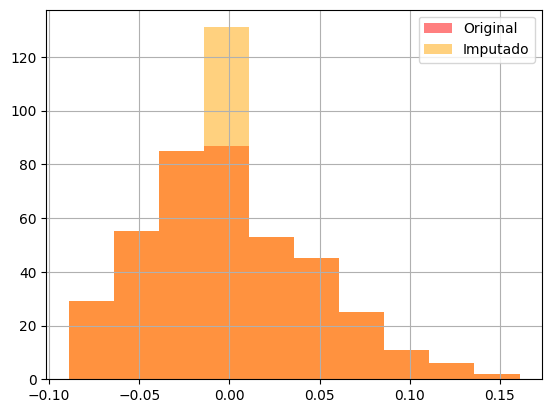

In [34]:
# Guardamos en variables separadas las Series de la columna 'bmi' (antes y después de la imputación)
before = data['bmi']             # Contiene los datos originales con sus valores nulos
after = df_clean_simple['bmi']   # Contiene los datos imputados con la media simple

# Dibujamos el primer histograma para la distribución original
# color='red' le da el tono rojo, alpha=0.5 hace la barra semi-transparente para ver a través de ella,
# y label='Original' le asigna la etiqueta que usará la leyenda.
before.hist(color='red', alpha=0.5, label='Original')

#Dibujamos el segundo histograma para la distribución imputada superpuesto en el mismo lienzo
# color='orange' asigna tono naranja, alpha=0.5 mantiene la transparencia para comparar la superposición.
after.hist(color='orange', alpha=0.5, label='Imputado')

# Muestra el recuadro con la simbología de los colores según las etiquetas ('label') asignadas
plt.legend()

# Despliega la gráfica final renderizada en pantalla
plt.show()

